# GLD proxy forecasting: ARIMA, GARCH, and AR reference

This notebook reads persisted results from the reproducible package. GLD is a provisional price proxy with unverified units, instrument and adjustment policy. The data ends August 14, 2025; final forecasts are historical as-of forecasts, not current predictions. No exchange calendar has been validated.

In [1]:
from pathlib import Path
import os, json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
if not (root / 'pyproject.toml').exists():
    root = root.parent
candidates = sorted((root / 'outputs').glob('*/comparison.html'), key=lambda p: p.stat().st_mtime)
run = Path(os.environ['GOLD_RUN_DIR']) if 'GOLD_RUN_DIR' in os.environ else candidates[-1].parent
manifest = json.loads((run / 'manifest.json').read_text())
quality = json.loads((run / 'quality_report.json').read_text())
display(quality)
display(manifest)

{'sha256': '1ccca1ac6b9da9f66ee085b0d5b0e45994c0b2c00e292693424862af43b6890c',
 'observations': 2666,
 'start': '2015-01-02',
 'end': '2025-08-14',
 'split_counts': [1760, 501, 405],
 'weekend_observations': 0,
 'gaps_over_four_days': {'2025-04-22': 5},
 'calendar': 'Unverified: use observed sessions only; no filling or missing-session claims',
 'target': 'GLD gold-price proxy; instrument, units, adjustment and licensing unverified'}

{'run_id': 'full-20261004-ar',
 'input_sha256': '1ccca1ac6b9da9f66ee085b0d5b0e45994c0b2c00e292693424862af43b6890c',
 'config': {'input': 'gold_data_2015_25.csv',
  'target': 'GLD',
  'train_end': '2021-12-31',
  'validation_end': '2023-12-31',
  'horizons': [1, 5, 20],
  'orders': [0, 1, 2, 3],
  'simulations': 10000,
  'seed': 706,
  'bootstrap_samples': 2000,
  'bootstrap_blocks': [20, 10, 40],
  'expected_counts': [1760, 501, 405],
  'output': 'outputs'},
 'lockfile_sha256': '52cafed49510bdf5143af18825563ed97b618f10149231c7b8337c67835b430c',
 'timestamp_utc': '2026-10-05T03:28:02.578039+00:00',
 'python': '3.13.15',
 'packages': {'gold-forecast': '0.1.0',
  'numpy': '2.5.3',
  'pandas': '2.3.3',
  'scipy': '1.18.1',
  'statsmodels': '0.14.5',
  'arch': '7.2.0',
  'matplotlib': '3.11.2'},
 'seed_rule': 'base + origin_offset * 31 + model_index; final base + 100000 + model_index; Naive=0, ARIMA=1, GARCH=2, AR=3',
 'variance_units': 'percentage log-return squared; decimal variance divid

## Frozen chronological experiment

Order selection uses expanding validation histories only. Every test forecast is refitted through its origin, and eligible targets remain inside the test segment. The primary criterion is one-session price MAE. Price point estimates are simulated medians; uncertainty uses coherent cumulative-return paths. Complete-system comparisons cannot isolate the effect of changing variance alone.

New runs include a fixed AR(1) reference on percentage log returns, alongside the last-price baseline. Its lag is not tuned. Runs extended after the original evaluation label AR comparisons as retrospective and exploratory.

In [2]:
display(json.loads((run / 'frozen.json').read_text()))
display(pd.read_csv(run / 'tuning_scores.csv'))
display(pd.read_csv(run / 'simulation_stability.csv'))
display(json.loads((run / 'diagnostics.json').read_text()))

{'order': [3, 1],
 'criterion': 'validation one-session price MAE',
 'config': {'input': 'gold_data_2015_25.csv',
  'target': 'GLD',
  'train_end': '2021-12-31',
  'validation_end': '2023-12-31',
  'horizons': [1, 5, 20],
  'orders': [0, 1, 2, 3],
  'simulations': 10000,
  'seed': 706,
  'bootstrap_samples': 2000,
  'bootstrap_blocks': [20, 10, 40],
  'expected_counts': [1760, 501, 405],
  'output': 'outputs'},
 'selected_file': 'validation_arima_3_1.csv',
 'validation_end': '2023-12-29',
 'models': ['Naive', 'ARIMA', 'GARCH', 'AR'],
 'ar_order': 1,
 'reference_extension': {'source_run': '/Users/stevenxu/Desktop/IDS706/AIProject/outputs/full-20261004',
  'note': 'Fixed AR(1) added after original evaluation; AR comparisons are exploratory.'}}

,p,q,mae,attempted,failures,file
0,0,0,1.196235,501,0,validation_arima_0_0.csv
1,0,1,1.199213,501,0,validation_arima_0_1.csv
2,0,2,1.193589,501,0,validation_arima_0_2.csv
3,0,3,1.192326,501,0,validation_arima_0_3.csv
4,1,0,1.199147,501,0,validation_arima_1_0.csv
5,1,1,1.196859,501,0,validation_arima_1_1.csv
6,1,2,1.192725,501,0,validation_arima_1_2.csv
7,1,3,1.192109,501,0,validation_arima_1_3.csv
8,2,0,1.193648,501,0,validation_arima_2_0.csv
9,2,1,1.195482,501,0,validation_arima_2_1.csv


,model,origin,horizon,base_seed,audit_seed,base_paths,audit_paths,base_status,audit_status,point_price_relative_change,lower80_relative_change,upper80_relative_change,lower95_relative_change,upper95_relative_change
0,Naive,2021-12-31,1,706,707,10000,20000,ok,ok,0.000000e+00,0.000031,0.000032,0.000019,0.000020
1,Naive,2021-12-31,5,706,707,10000,20000,ok,ok,0.000000e+00,0.000372,0.000391,0.000148,0.000160
2,Naive,2021-12-31,20,706,707,10000,20000,ok,ok,0.000000e+00,0.001421,0.001571,0.002063,0.002408
3,ARIMA,2021-12-31,1,706,707,10000,20000,ok,ok,1.882589e-12,0.000031,0.000032,0.000019,0.000020
4,ARIMA,2021-12-31,5,706,707,10000,20000,ok,ok,8.875633e-12,0.000372,0.000392,0.000148,0.000160
5,ARIMA,2021-12-31,20,706,707,10000,20000,ok,ok,3.814221e-11,0.001427,0.001578,0.002072,0.002418
6,GARCH,2021-12-31,1,706,707,10000,20000,ok,ok,1.222918e-12,0.000025,0.000025,0.000016,0.000016
7,GARCH,2021-12-31,5,706,707,10000,20000,ok,ok,6.797869e-12,0.000382,0.000398,0.000154,0.000164
8,GARCH,2021-12-31,20,706,707,10000,20000,ok,ok,7.526882e-11,0.000906,0.000983,0.001415,0.001609
9,AR,2021-12-31,1,706,707,10000,20000,ok,ok,1.880927e-12,0.000031,0.000032,0.000019,0.000020


{'adf_pvalue': 0.0,
 'kpss_pvalue': 0.1,
 'arch_pvalue': 1.3557646160743576e-21,
 'acf': [1.0,
  0.030940270241661714,
  -0.023410071398172985,
  0.018131449486519763,
  -0.00716568794596994,
  -0.06319500245801789,
  -0.0027234955218698323,
  -0.021959011114316137,
  0.02063987509815069,
  -0.003591848737996929,
  -0.015297911094806587,
  0.01673616236708306,
  0.03198633928104119,
  0.03324363741733854,
  0.005175660060890334,
  -0.009014033260457605,
  -0.013425346693276843,
  -0.054121012883676274,
  0.017020114226703083,
  -0.01343609178556271,
  -0.05387086166700952],
 'pacf': [1.0,
  0.030957869940320234,
  -0.024418511335650064,
  0.019692241999959753,
  -0.008980743567114254,
  -0.06206288174880806,
  0.0005375073503663858,
  -0.024840992667276525,
  0.02457314317336485,
  -0.007096258458404084,
  -0.01715630102914961,
  0.01652555781784138,
  0.028021994769486563,
  0.03605342636484017,
  0.0024916795061785796,
  -0.009664691972858467,
  -0.012435013877937733,
  -0.0512449021

## Held-out accuracy and uncertainty

Lower MAE, RMSE and interval score are better. Coverage should be considered against the nominal level together with width and score. QLIKE uses a noisy squared daily return proxy. Failed fits and common-pair counts are explicitly reported.

In [3]:
from gold_forecast.metrics import summarize
forecasts = pd.read_csv(run / 'test_forecasts.csv')
scores = pd.read_csv(run / 'scores.csv')
pd.testing.assert_frame_equal(scores, summarize(forecasts), check_dtype=False, rtol=1e-8, atol=1e-10)
display(scores)
print((run / 'interpretation.txt').read_text())
display(pd.read_csv(run / 'paired_bootstrap.csv'))
display(pd.read_csv(run / 'scores_by_year.csv'))

,model,horizon,attempted,failures,n,valid_coverage,mae,rmse,error_min,error_max,...,error_p05,error_p95,qlike,coverage80,width80,interval_score80,coverage95,width95,interval_score95,mae_improvement_vs_naive_percent
0,AR,1,405,0,405,1.0,2.018323,2.704955,-8.803218,10.066849,...,-4.371005,4.257521,1.126610,0.753086,5.627278,9.500380,0.911111,8.598656,13.860966,0.168444
1,AR,5,401,0,401,1.0,4.247307,5.671729,-18.109008,22.142236,...,-8.016023,9.587673,NaN,0.778055,12.722479,19.955363,0.925187,19.446449,28.741165,1.811956
2,AR,20,386,0,386,1.0,7.911857,10.075360,-16.336605,35.262706,...,-9.146811,19.228689,NaN,0.774611,25.334616,35.456802,0.948187,38.725713,45.315726,6.555057
3,ARIMA,1,405,0,405,1.0,2.024127,2.718702,-8.984074,10.085461,...,-4.423650,4.264647,1.127380,0.755556,5.622015,9.576055,0.903704,8.597224,13.952523,-0.118667
4,ARIMA,5,401,0,401,1.0,4.245438,5.681156,-18.272191,22.384659,...,-8.154291,9.540006,NaN,0.773067,12.594674,20.034703,0.920200,19.267561,29.056277,1.855146
5,ARIMA,20,386,0,386,1.0,7.917123,10.080723,-16.392024,35.401152,...,-9.061532,19.280962,NaN,0.772021,25.277186,35.485006,0.953368,38.704808,45.011312,6.492869
6,GARCH,1,405,0,405,1.0,2.016892,2.704825,-8.713494,10.127467,...,-4.403198,4.253533,1.025261,0.787654,6.288182,9.145442,0.938272,9.614355,12.307375,0.239223
7,GARCH,5,401,0,401,1.0,4.281313,5.703372,-17.914007,22.317260,...,-7.877035,9.787006,NaN,0.793017,13.826958,20.237181,0.925187,21.550718,29.799709,1.025804
8,GARCH,20,386,0,386,1.0,8.154635,10.416008,-15.569470,35.999858,...,-8.357120,20.105140,NaN,0.756477,27.140146,40.574801,0.901554,42.611367,54.171103,3.687672
9,Naive,1,405,0,405,1.0,2.021728,2.708304,-8.649994,10.179993,...,-4.373999,4.309998,1.126374,0.750617,5.626791,9.505138,0.906173,8.603601,13.912275,0.000000


Lowest one-session price MAE: GARCH. Among ARIMA and GARCH: GARCH. Naive minus ARIMA MAE difference: -0.0024, paired 95% CI [-0.0214, 0.0144]; evidence inconclusive (interval includes zero). Naive minus GARCH MAE difference: 0.0048, paired 95% CI [0.0027, 0.0080]; evidence favors GARCH. Naive minus AR MAE difference: 0.0034, paired 95% CI [-0.0037, 0.0117]; evidence inconclusive (interval includes zero). ARIMA minus GARCH MAE difference: 0.0072, paired 95% CI [-0.0088, 0.0263]; evidence inconclusive (interval includes zero). ARIMA minus AR MAE difference: 0.0058, paired 95% CI [-0.0083, 0.0217]; evidence inconclusive (interval includes zero). GARCH minus AR MAE difference: -0.0014, paired 95% CI [-0.0073, 0.0043]; evidence inconclusive (interval includes zero). At 1 sessions, lowest 80% interval score: GARCH, empirical coverage 78.8%. At 1 sessions, lowest 95% interval score: GARCH, empirical coverage 93.8%. At 5 sessions, lowest 80% interval score: AR, empirical coverage 77.8%. At 5 s

,horizon,loss,model_a,model_b,mean_difference,lower95,upper95,block,effective_block,inference_status,seed,n
0,1,absolute_loss,Naive,ARIMA,-0.002399,-0.021387,0.014450,20,20,ok,826,405
1,1,absolute_loss,Naive,ARIMA,-0.002399,-0.018494,0.013344,10,10,ok,816,405
2,1,absolute_loss,Naive,ARIMA,-0.002399,-0.026363,0.017613,40,40,ok,846,405
3,1,absolute_loss,Naive,GARCH,0.004836,0.002718,0.008029,20,20,ok,826,405
4,1,absolute_loss,Naive,GARCH,0.004836,0.002132,0.008504,10,10,ok,816,405
...,...,...,...,...,...,...,...,...,...,...,...,...
157,20,interval95,ARIMA,AR,-0.304413,-0.609264,-0.057336,10,10,ok,2716,386
158,20,interval95,ARIMA,AR,-0.304413,-0.613399,-0.026121,40,40,ok,2746,386
159,20,interval95,GARCH,AR,8.855378,4.345303,14.905205,20,20,ok,2726,386
160,20,interval95,GARCH,AR,8.855378,4.822737,13.727651,10,10,ok,2716,386


,model,horizon,attempted,failures,n,valid_coverage,mae,rmse,error_min,error_max,...,error_p95,qlike,coverage80,width80,interval_score80,coverage95,width95,interval_score95,mae_improvement_vs_naive_percent,year
0,AR,1,252,0,252,1.0,1.630599,2.142918,-7.920234,5.006240,...,3.549653,0.908686,0.793651,5.004528,7.512915,0.928571,7.655805,10.712809,0.128564,2024
1,AR,5,248,0,248,1.0,3.545305,4.635038,-13.765988,12.908553,...,8.269736,NaN,0.798387,11.346971,16.695765,0.931452,17.343769,22.679310,1.176143,2024
2,AR,20,233,0,233,1.0,7.026364,8.499001,-16.336605,20.285800,...,14.614649,NaN,0.811159,22.686730,29.342274,0.961373,34.676437,37.178948,5.157494,2024
3,ARIMA,1,252,0,252,1.0,1.622453,2.137183,-7.765409,4.929913,...,3.542147,0.909112,0.801587,5.003545,7.506101,0.924603,7.644242,10.663095,0.627518,2024
4,ARIMA,5,248,0,248,1.0,3.544014,4.636278,-13.703802,13.047698,...,8.216549,NaN,0.794355,11.252584,16.724150,0.923387,17.223970,22.699236,1.212155,2024
5,ARIMA,20,233,0,233,1.0,7.032073,8.505742,-16.392024,20.245740,...,14.501211,NaN,0.815451,22.684828,29.428464,0.965665,34.727254,37.013607,5.080437,2024
6,GARCH,1,252,0,252,1.0,1.629590,2.142458,-7.858946,5.048926,...,3.576879,0.898489,0.801587,5.234712,7.536416,0.936508,8.009271,10.529761,0.190415,2024
7,GARCH,5,248,0,248,1.0,3.566214,4.657539,-13.576010,13.071413,...,8.448127,NaN,0.798387,11.517631,17.164797,0.919355,17.959261,25.268198,0.593334,2024
8,GARCH,20,233,0,233,1.0,7.231041,8.756034,-15.569470,20.808173,...,15.175403,NaN,0.781116,22.588690,33.070837,0.892704,35.386687,44.658117,2.394755,2024
9,Naive,1,252,0,252,1.0,1.632698,2.144405,-7.829987,5.080002,...,3.597999,0.908582,0.797619,5.014871,7.520267,0.924603,7.662295,10.627383,0.000000,2024


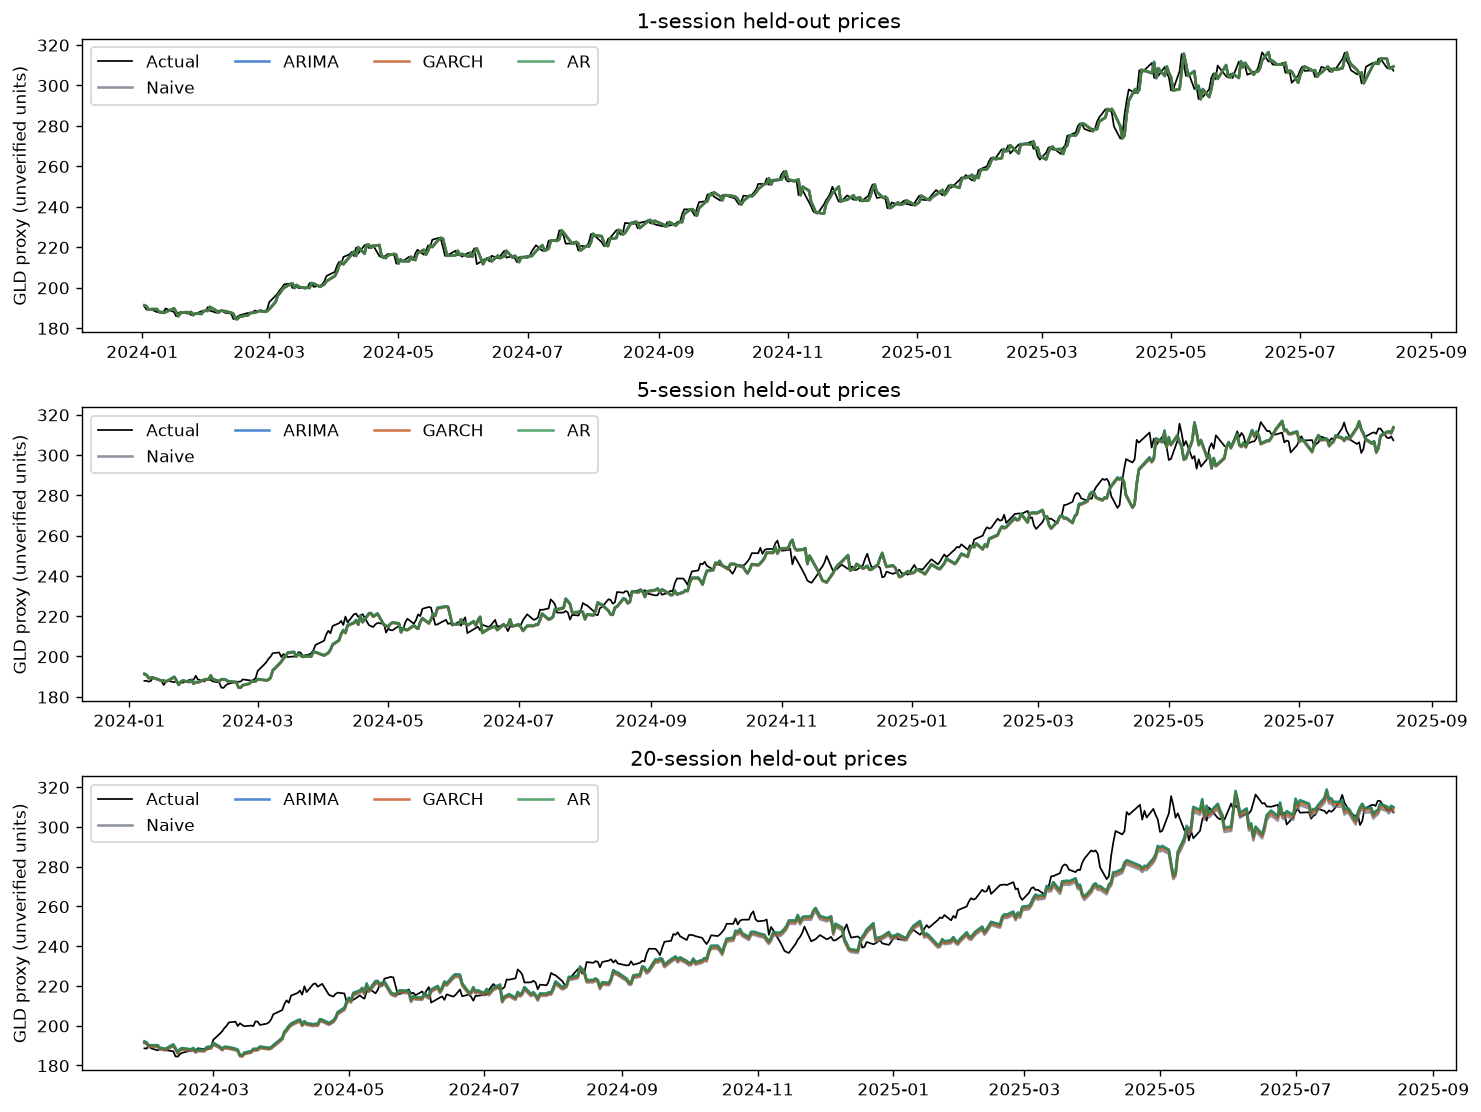

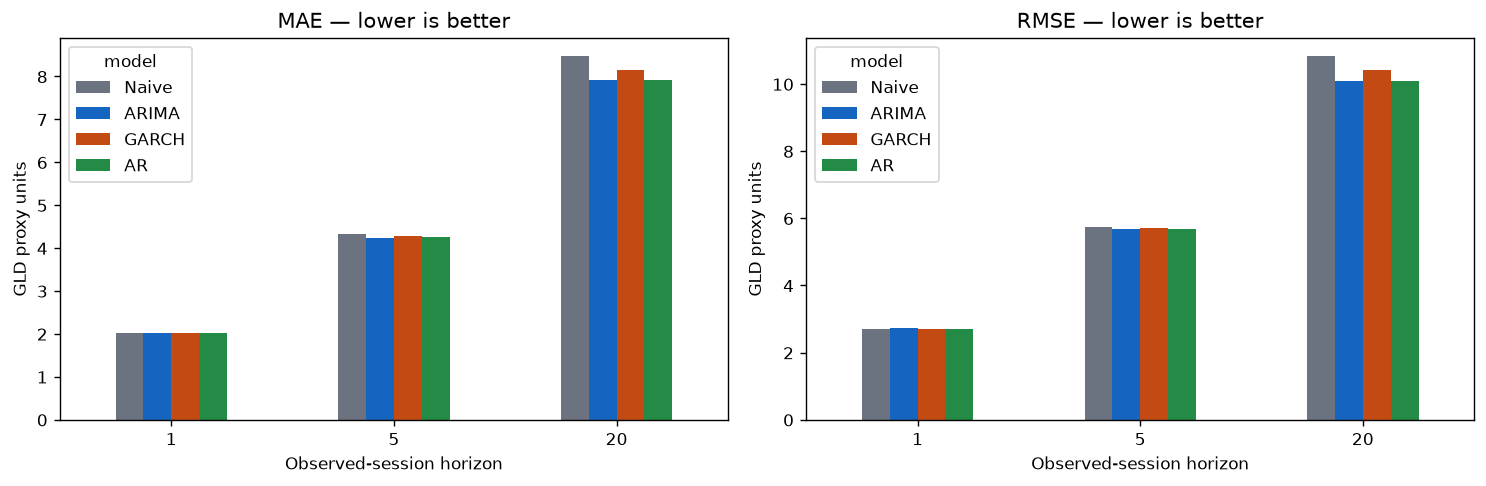

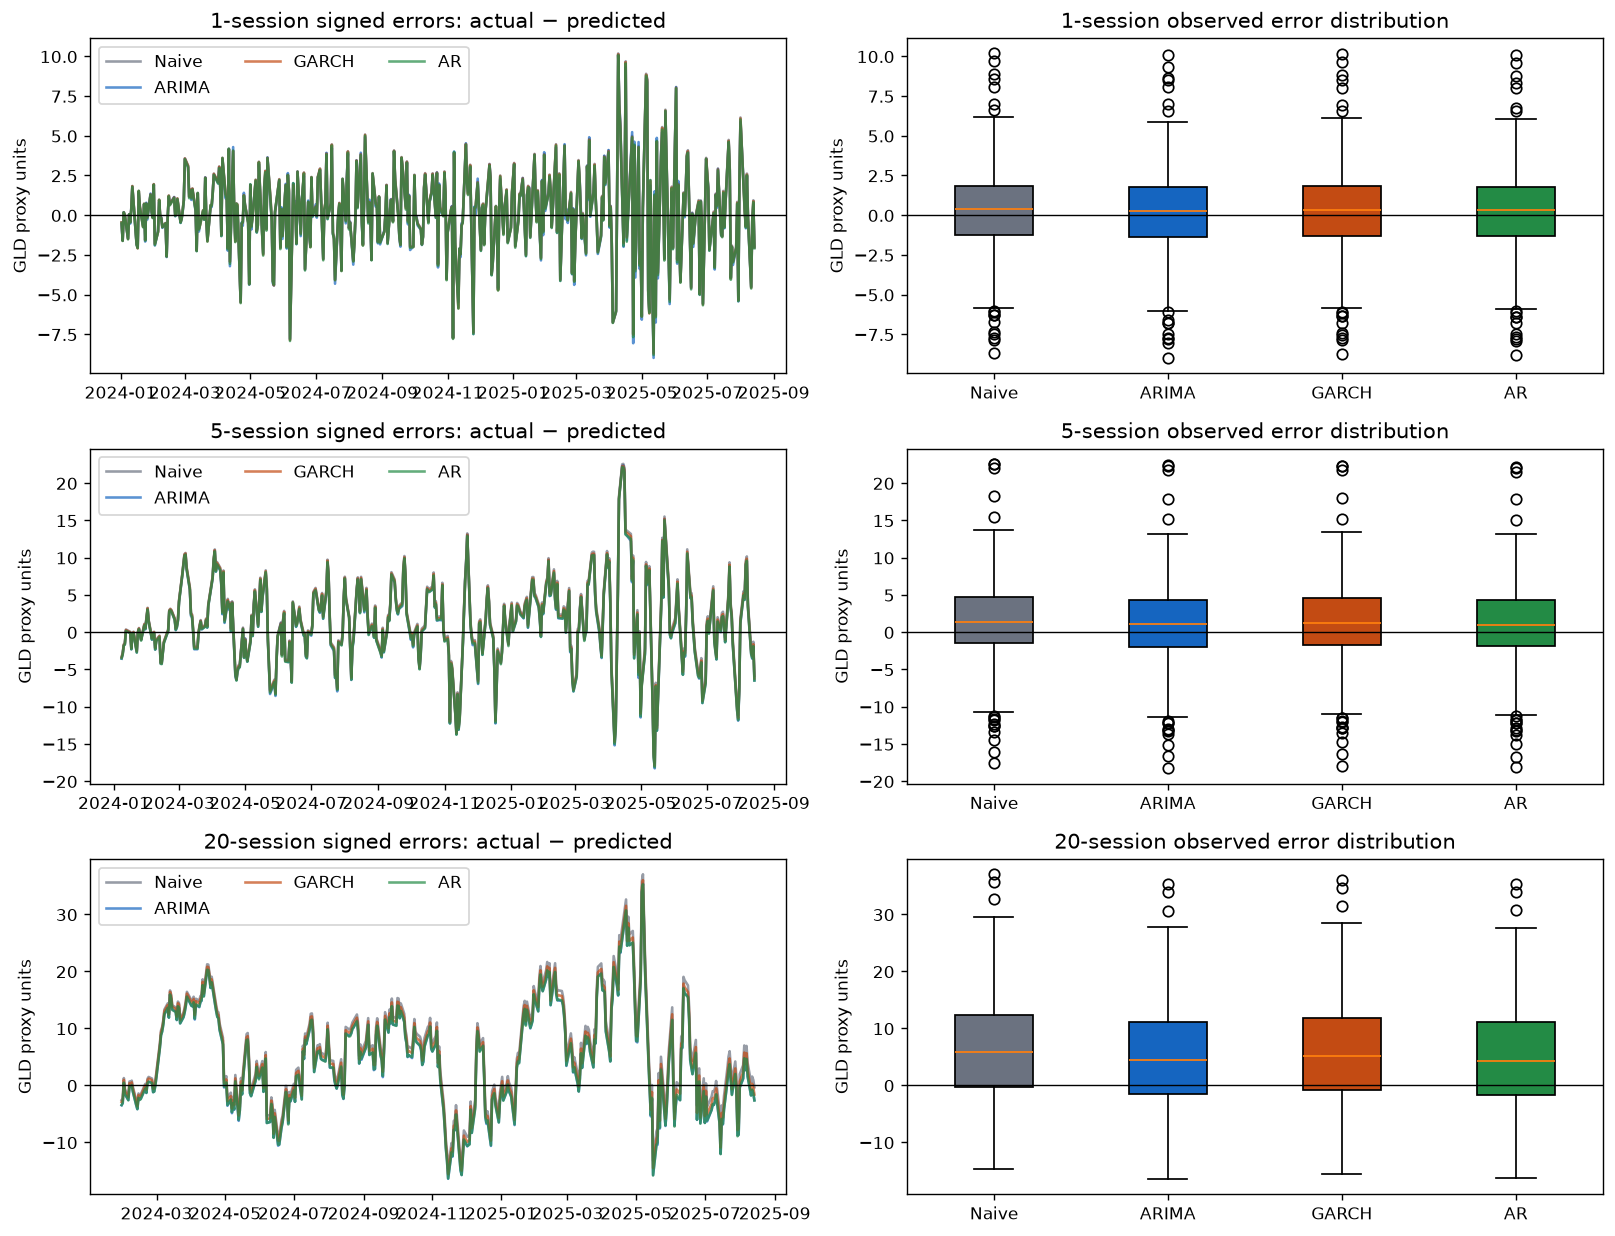

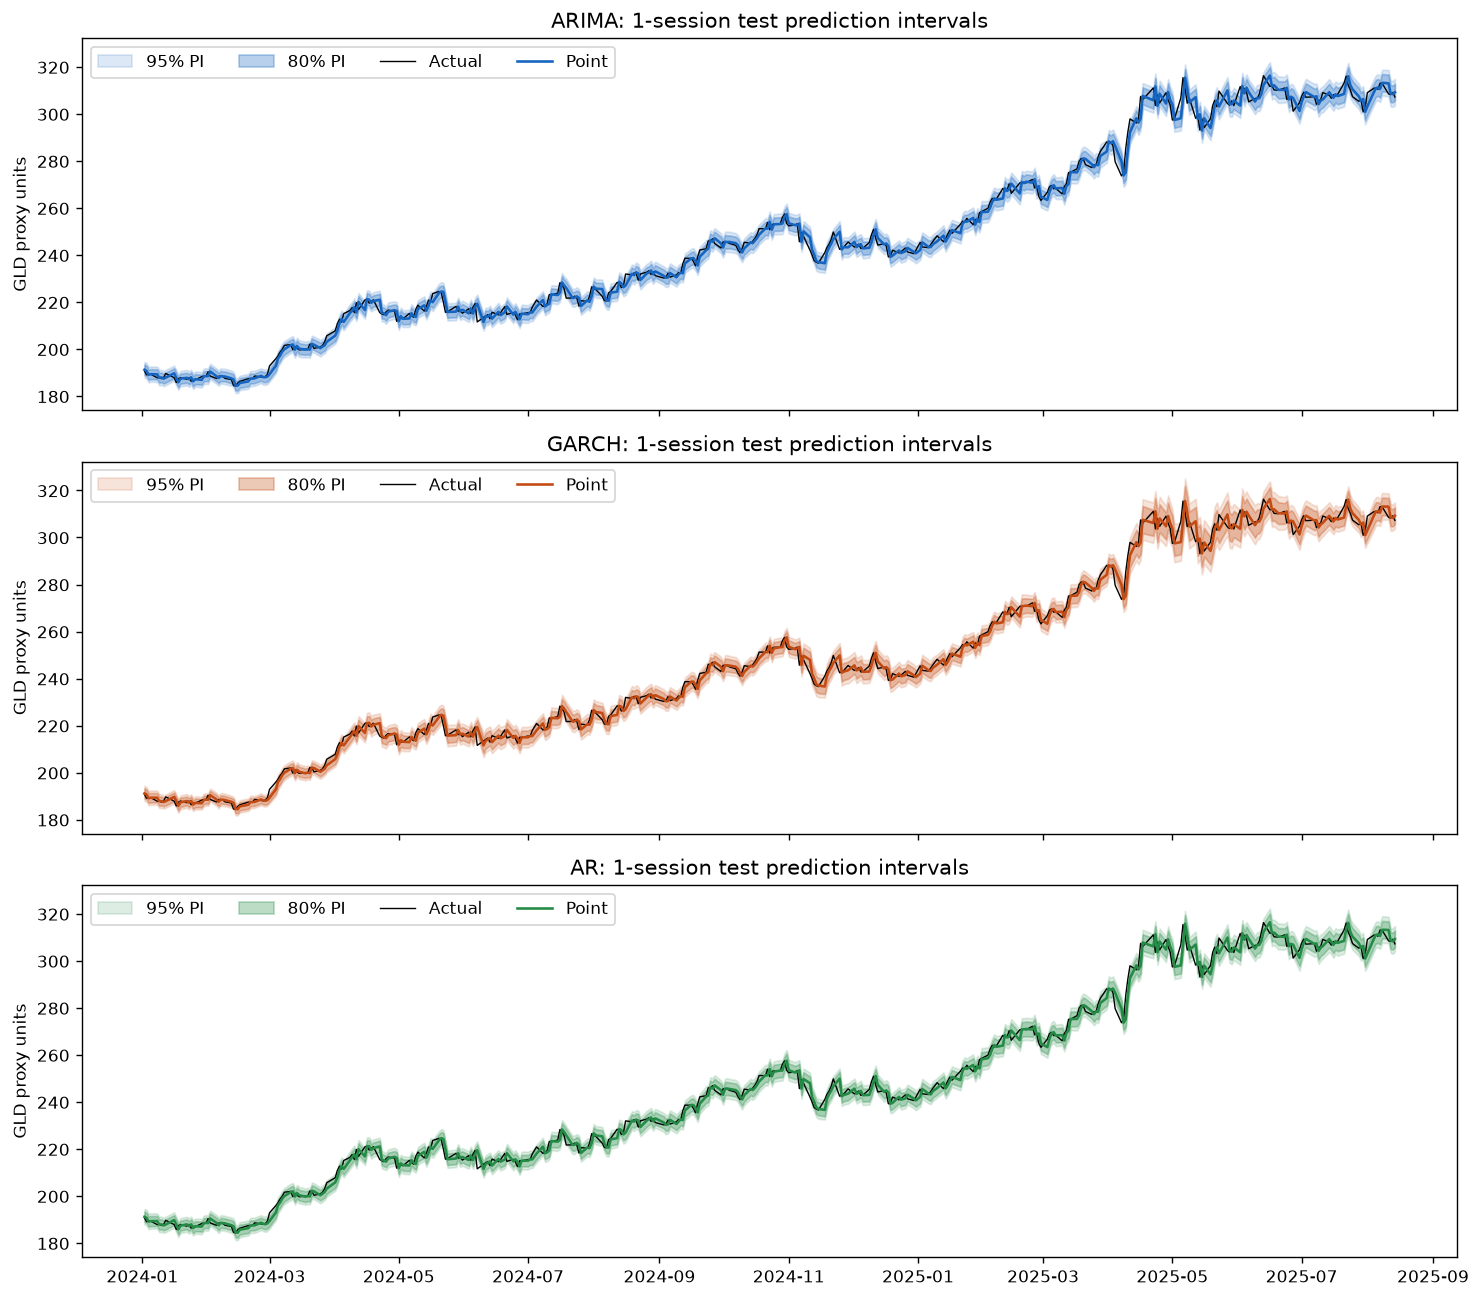

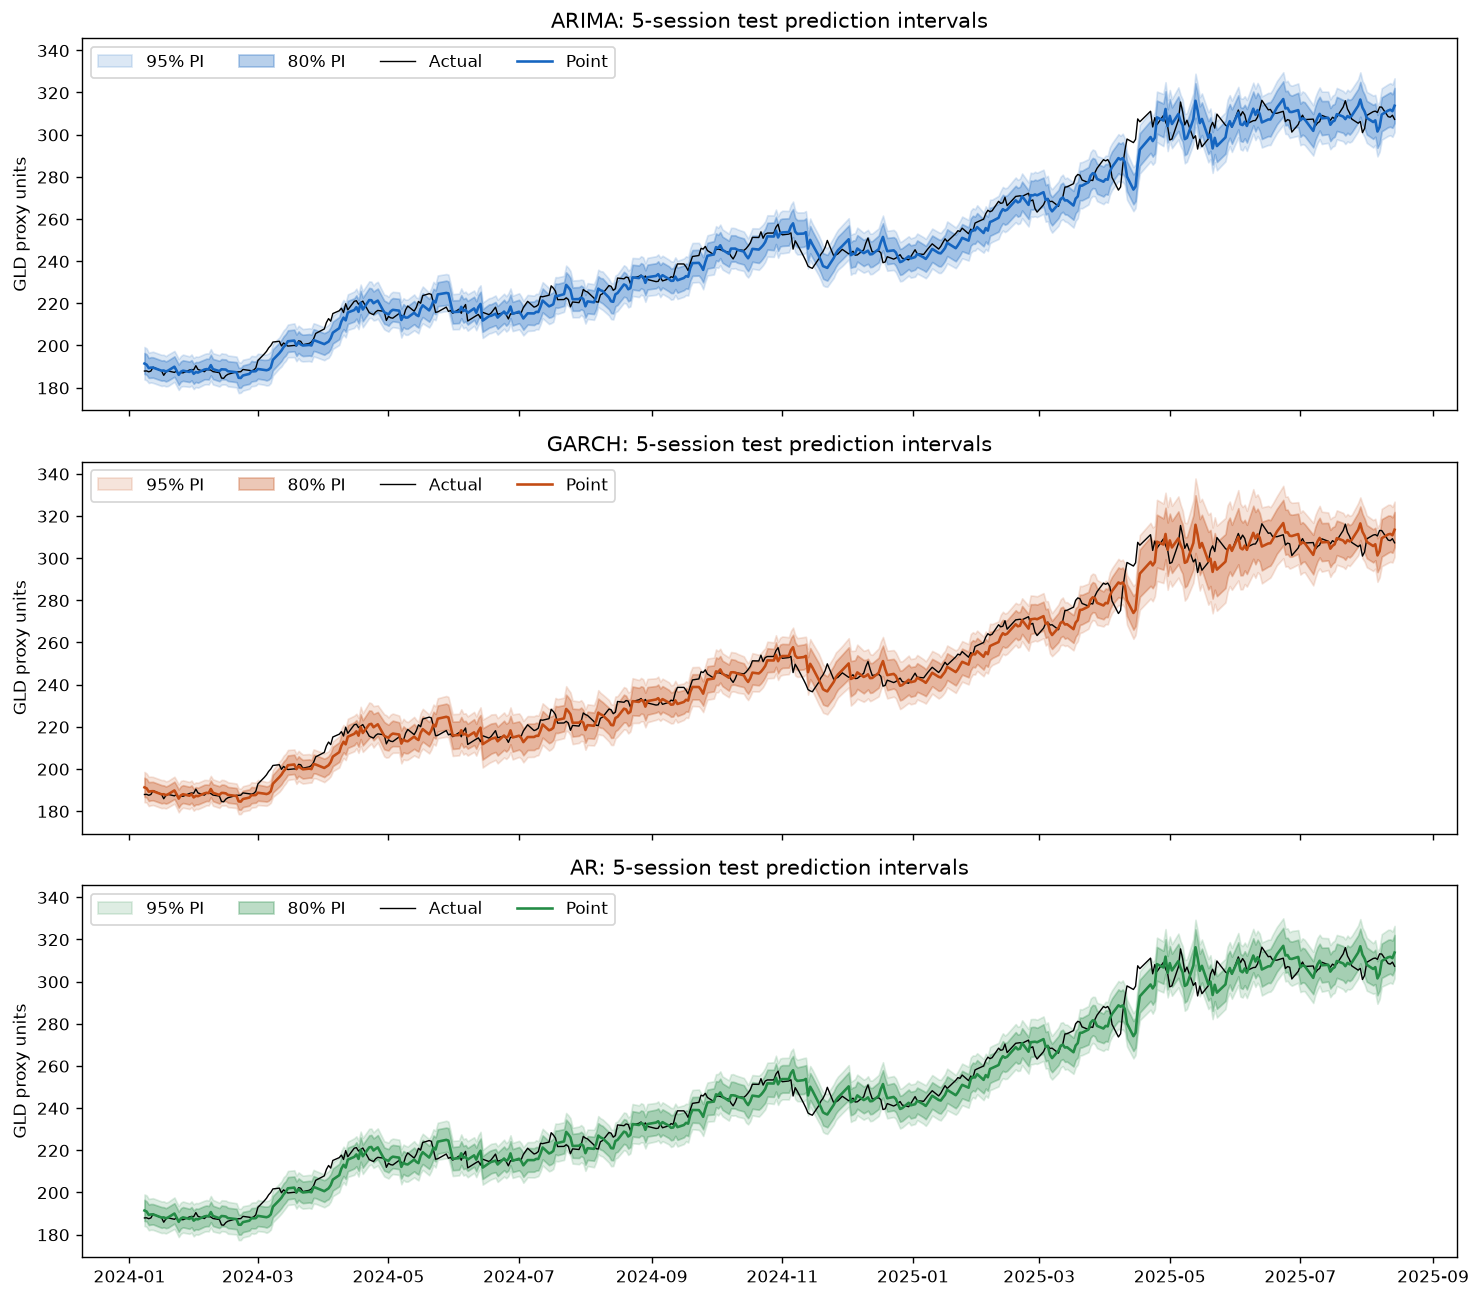

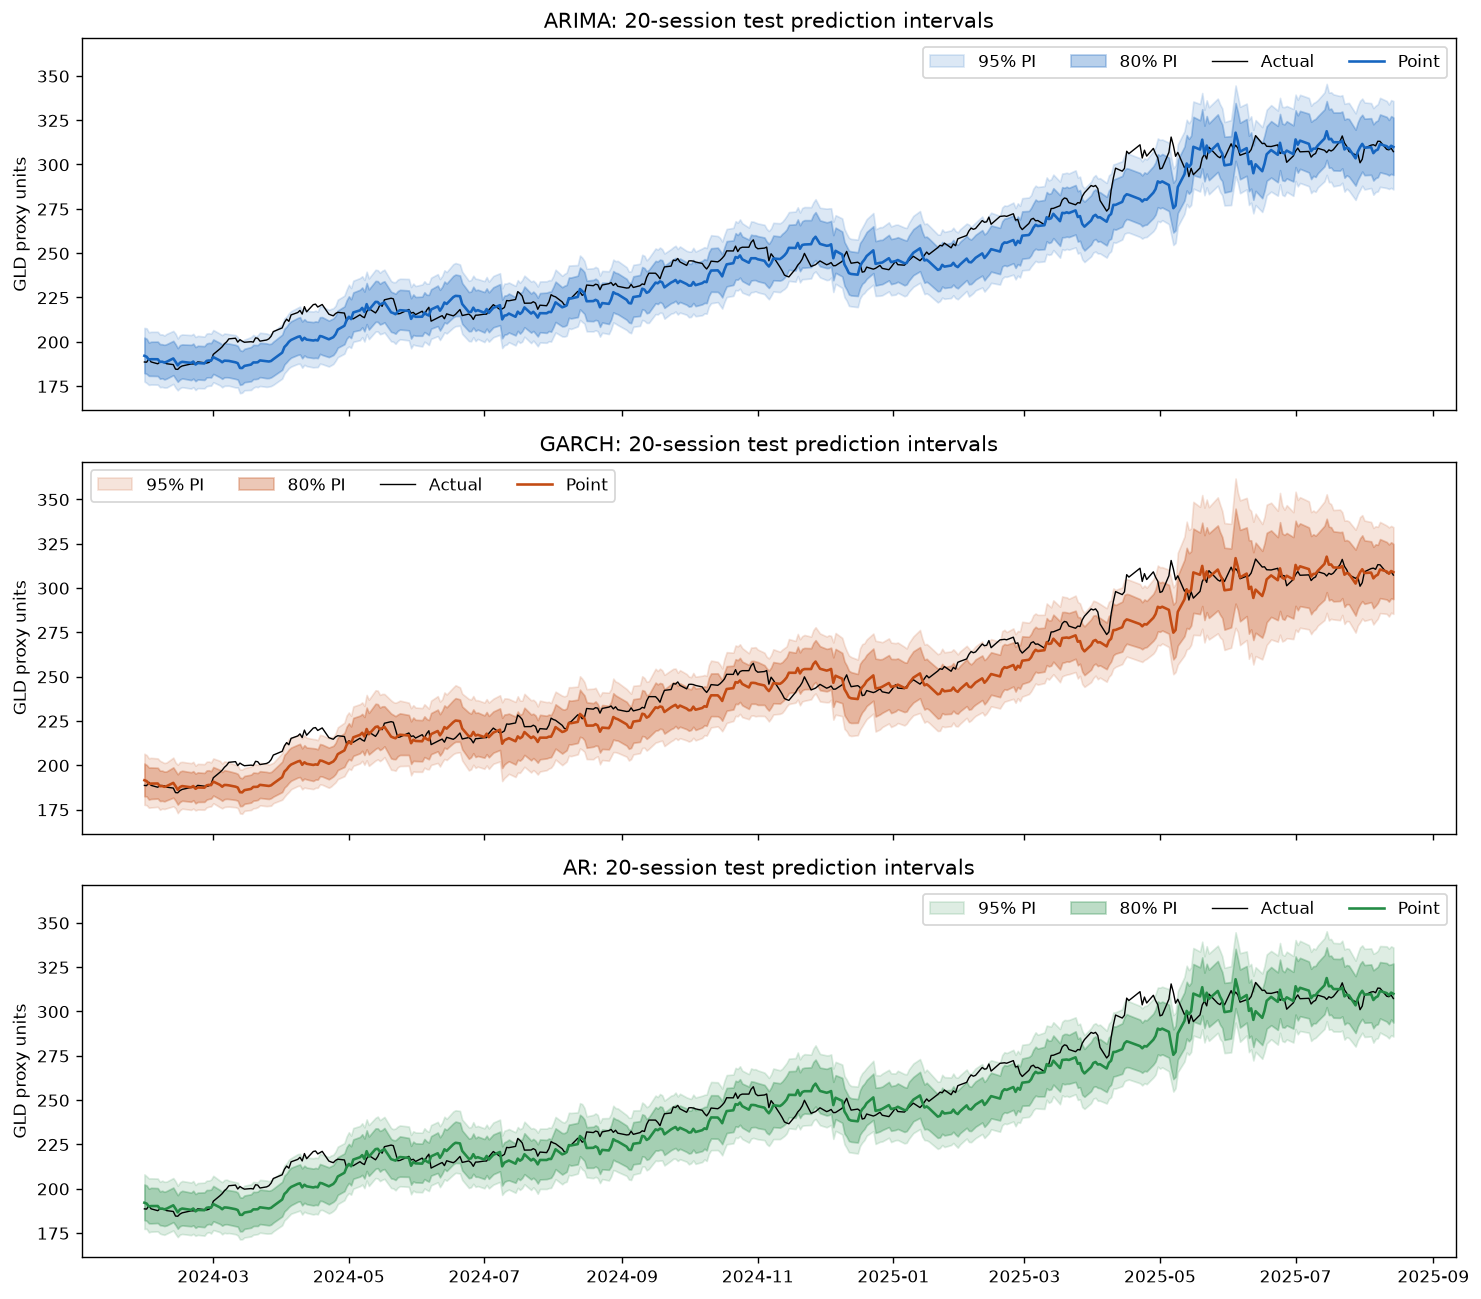

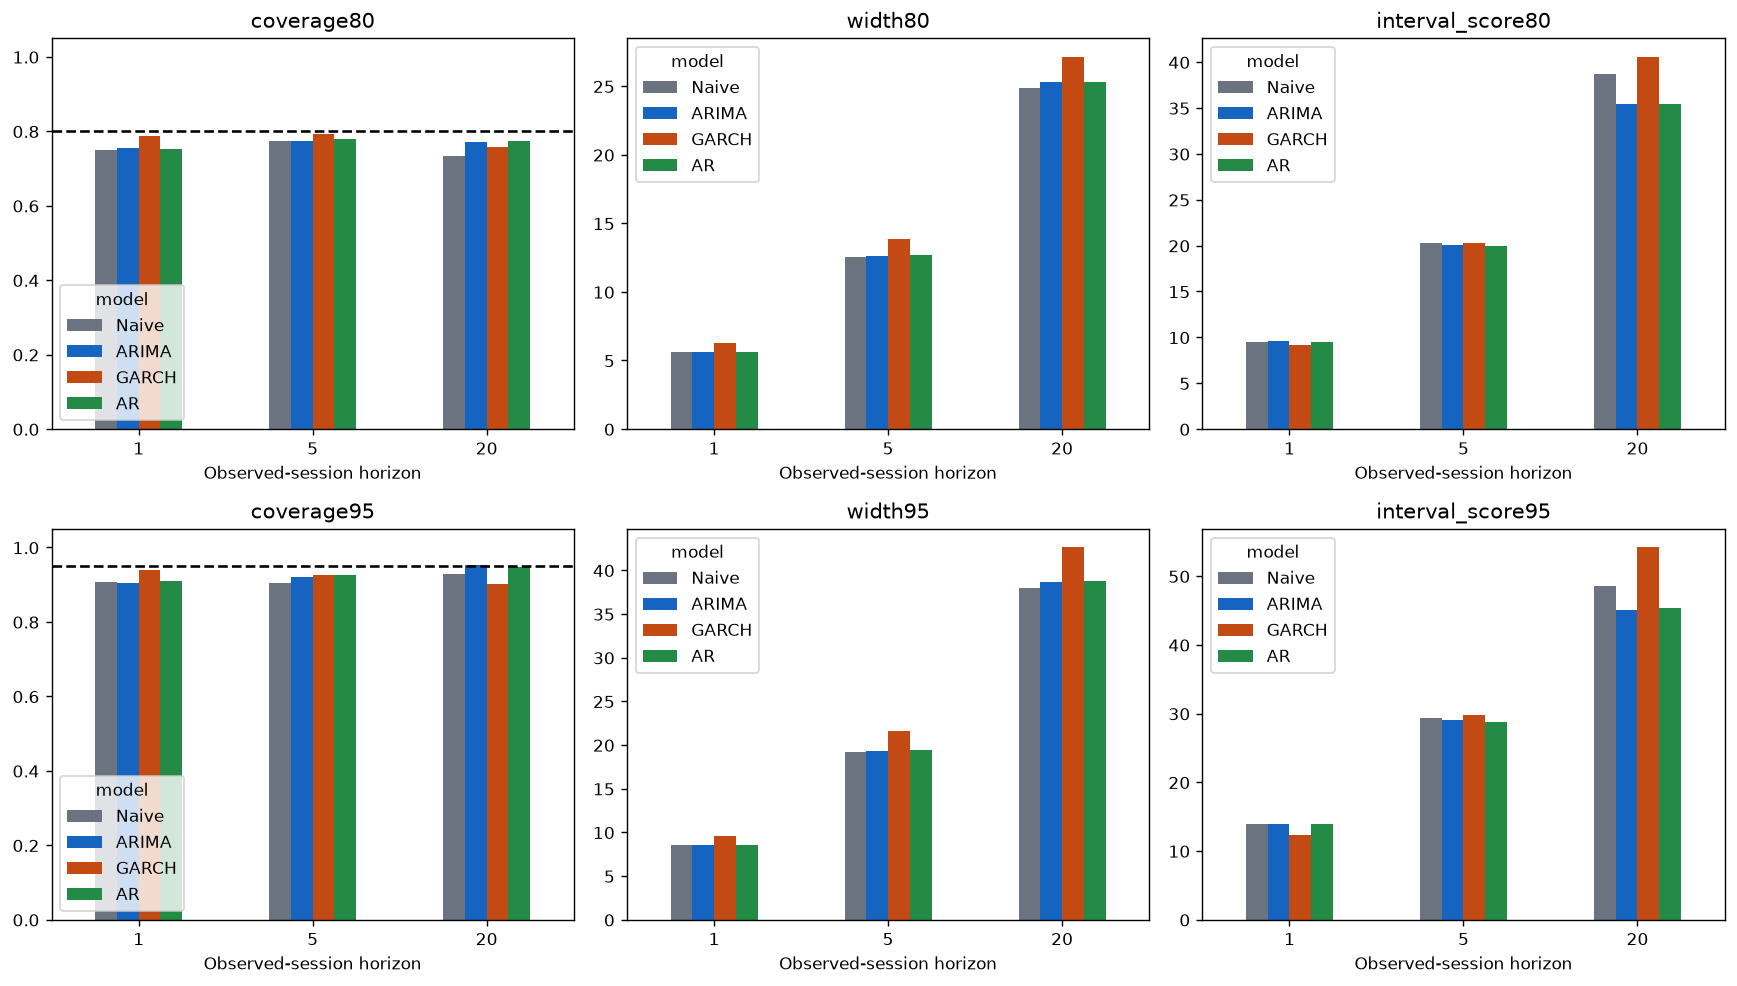

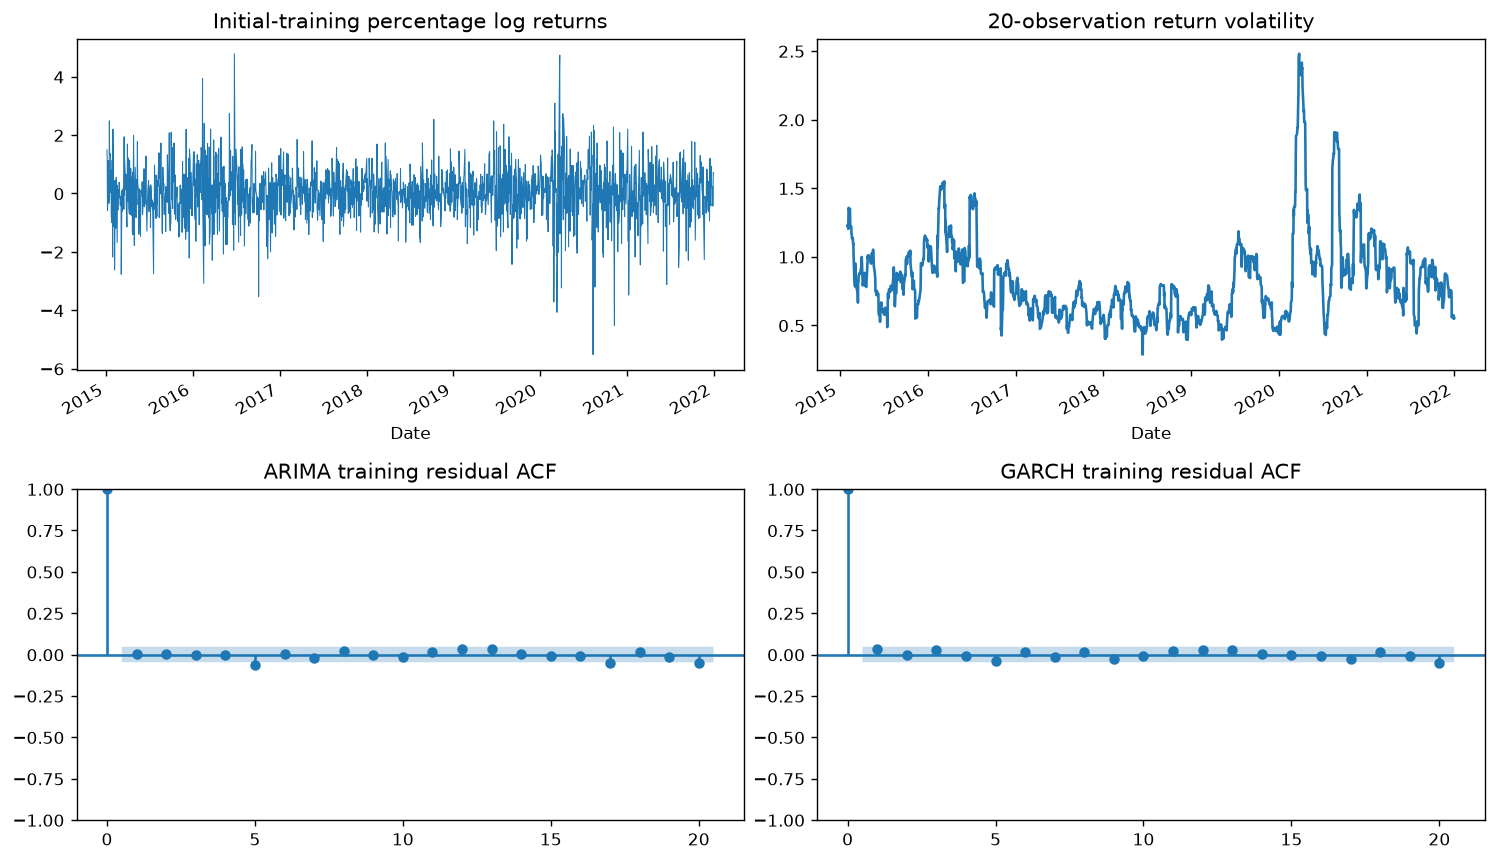

In [4]:
for name in ['actual_predictions', 'accuracy', 'errors', 'intervals_1', 'intervals_5', 'intervals_20', 'uncertainty_scores', 'diagnostics']:
    display(Image(filename=str(run / 'comparison_plots' / f'{name}.png')))

## Historical as-of forecasts

The following forecasts are anchored to the last observed date and use only future session steps. Actual outcomes and measured accuracy are unavailable. Gaussian fitted-parameter bands omit parameter uncertainty and may underrepresent tails. Historical error ranges shown above are not these forward prediction intervals.

,run_id,phase,model,origin,training_end,horizon,target_date,actual_price,actual_return_percent,fit_status,seed,point_price,lower80,upper80,lower95,upper95,return_variance_percent2,return_variance_decimal2
0,full-20261004-ar,final,Naive,2025-08-14,2025-08-14,1,NaN,NaN,NaN,ok,100706,307.250000,303.719082,310.821967,301.791067,312.807677,0.825405,0.000083
4,full-20261004-ar,final,Naive,2025-08-14,2025-08-14,5,NaN,NaN,NaN,ok,100706,307.250000,299.286451,315.425446,294.969437,320.041843,0.825405,0.000083
19,full-20261004-ar,final,Naive,2025-08-14,2025-08-14,20,NaN,NaN,NaN,ok,100706,307.250000,291.898730,323.408610,283.639490,332.825879,0.825405,0.000083
20,full-20261004-ar,final,ARIMA,2025-08-14,2025-08-14,1,NaN,NaN,NaN,ok,100707,307.308491,303.789177,310.868575,301.895615,312.818417,0.824099,0.000082
24,full-20261004-ar,final,ARIMA,2025-08-14,2025-08-14,5,NaN,NaN,NaN,ok,100707,307.805116,299.872765,315.947297,295.925544,320.161580,0.825084,0.000083
39,full-20261004-ar,final,ARIMA,2025-08-14,2025-08-14,20,NaN,NaN,NaN,ok,100707,309.525200,293.654956,326.253132,285.719054,335.314876,0.825084,0.000083
40,full-20261004-ar,final,GARCH,2025-08-14,2025-08-14,1,NaN,NaN,NaN,ok,100708,307.313148,303.793078,310.874004,301.994075,312.725906,0.789642,0.000079
44,full-20261004-ar,final,GARCH,2025-08-14,2025-08-14,5,NaN,NaN,NaN,ok,100708,307.565868,299.849698,315.480601,295.524577,320.097787,0.792558,0.000079
59,full-20261004-ar,final,GARCH,2025-08-14,2025-08-14,20,NaN,NaN,NaN,ok,100708,308.515422,293.339960,324.475961,285.253829,333.673928,0.801445,0.000080
60,full-20261004-ar,final,AR,2025-08-14,2025-08-14,1,NaN,NaN,NaN,ok,100709,307.346550,303.839371,310.894212,302.026694,312.760110,0.825026,0.000083


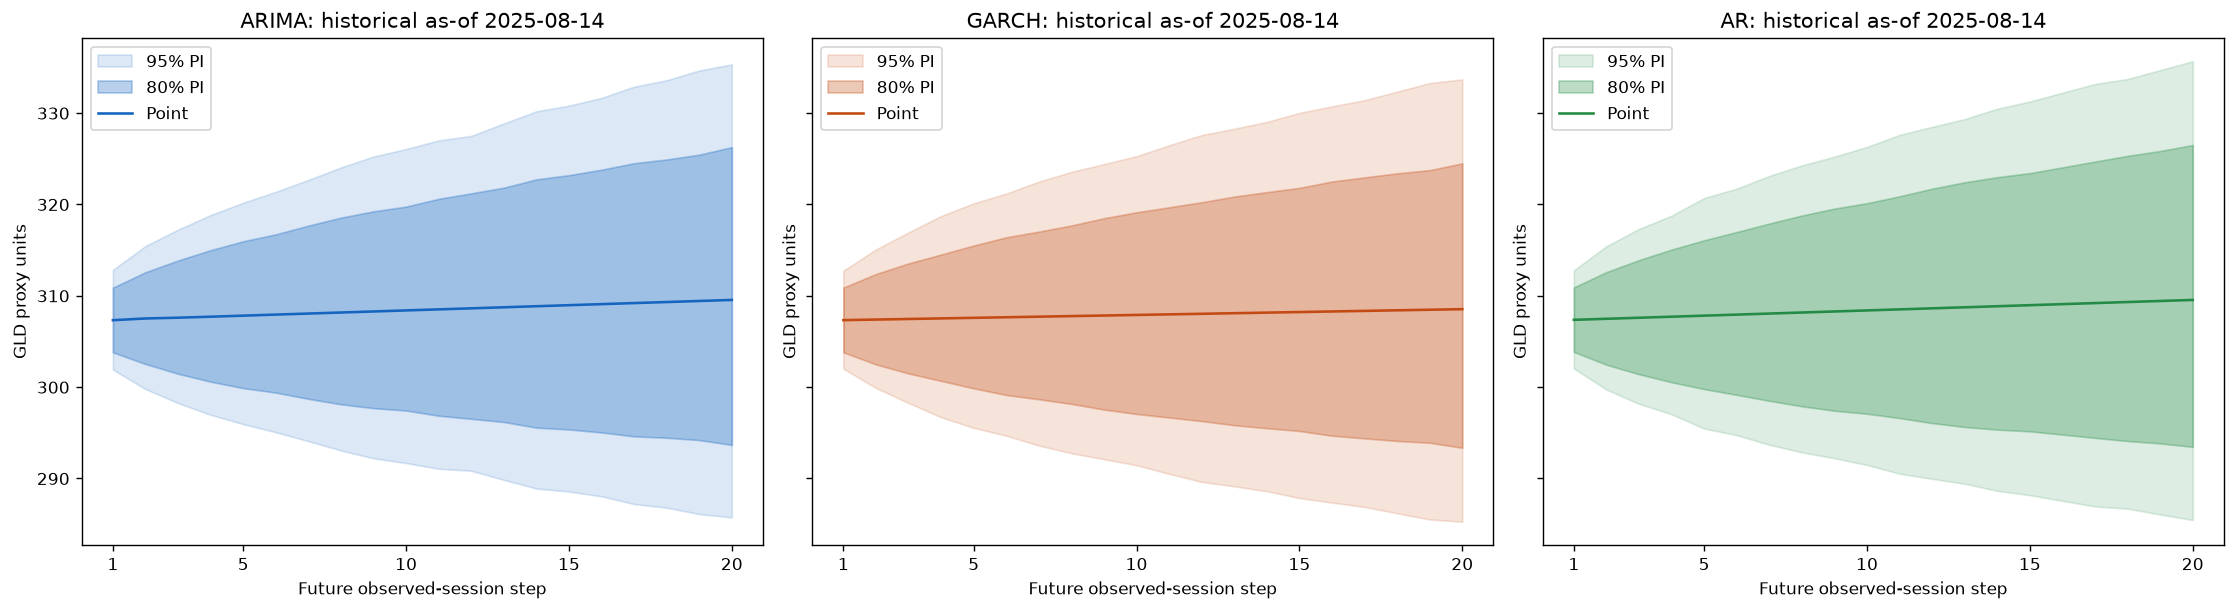

Standalone report: /Users/stevenxu/Desktop/IDS706/AIProject/outputs/full-20261004-ar/comparison.html


In [5]:
final = pd.read_csv(run / 'final_forecasts.csv')
assert final.actual_price.isna().all()
assert final.target_date.isna().all()
display(final[final.horizon.isin([1,5,20])].drop(columns='fit_details'))
display(Image(filename=str(run / 'comparison_plots' / 'final_forecasts.png')))
print('Standalone report:', run / 'comparison.html')

## 2024–2025 trend and projections through 2026
The black line is observed data through August 14, 2025. Everything after that cutoff—including all of 2026—is a forecast, not supplied actual data. Future dates assume the published NYSE holiday schedule; the dataset instrument remains unverified. The 2026 extension is separate from the evaluated 1/5/20-session forecasts and has no measured accuracy.

,model,target_date,point_price,lower80,upper80,lower95,upper95
346,ARIMA,2026-12-31,349.515526,282.259747,432.796755,251.097805,486.508048
693,GARCH,2026-12-31,329.960085,266.775829,408.109154,238.590651,456.319882
1040,AR,2026-12-31,349.534013,280.345736,435.797696,250.197227,488.310872


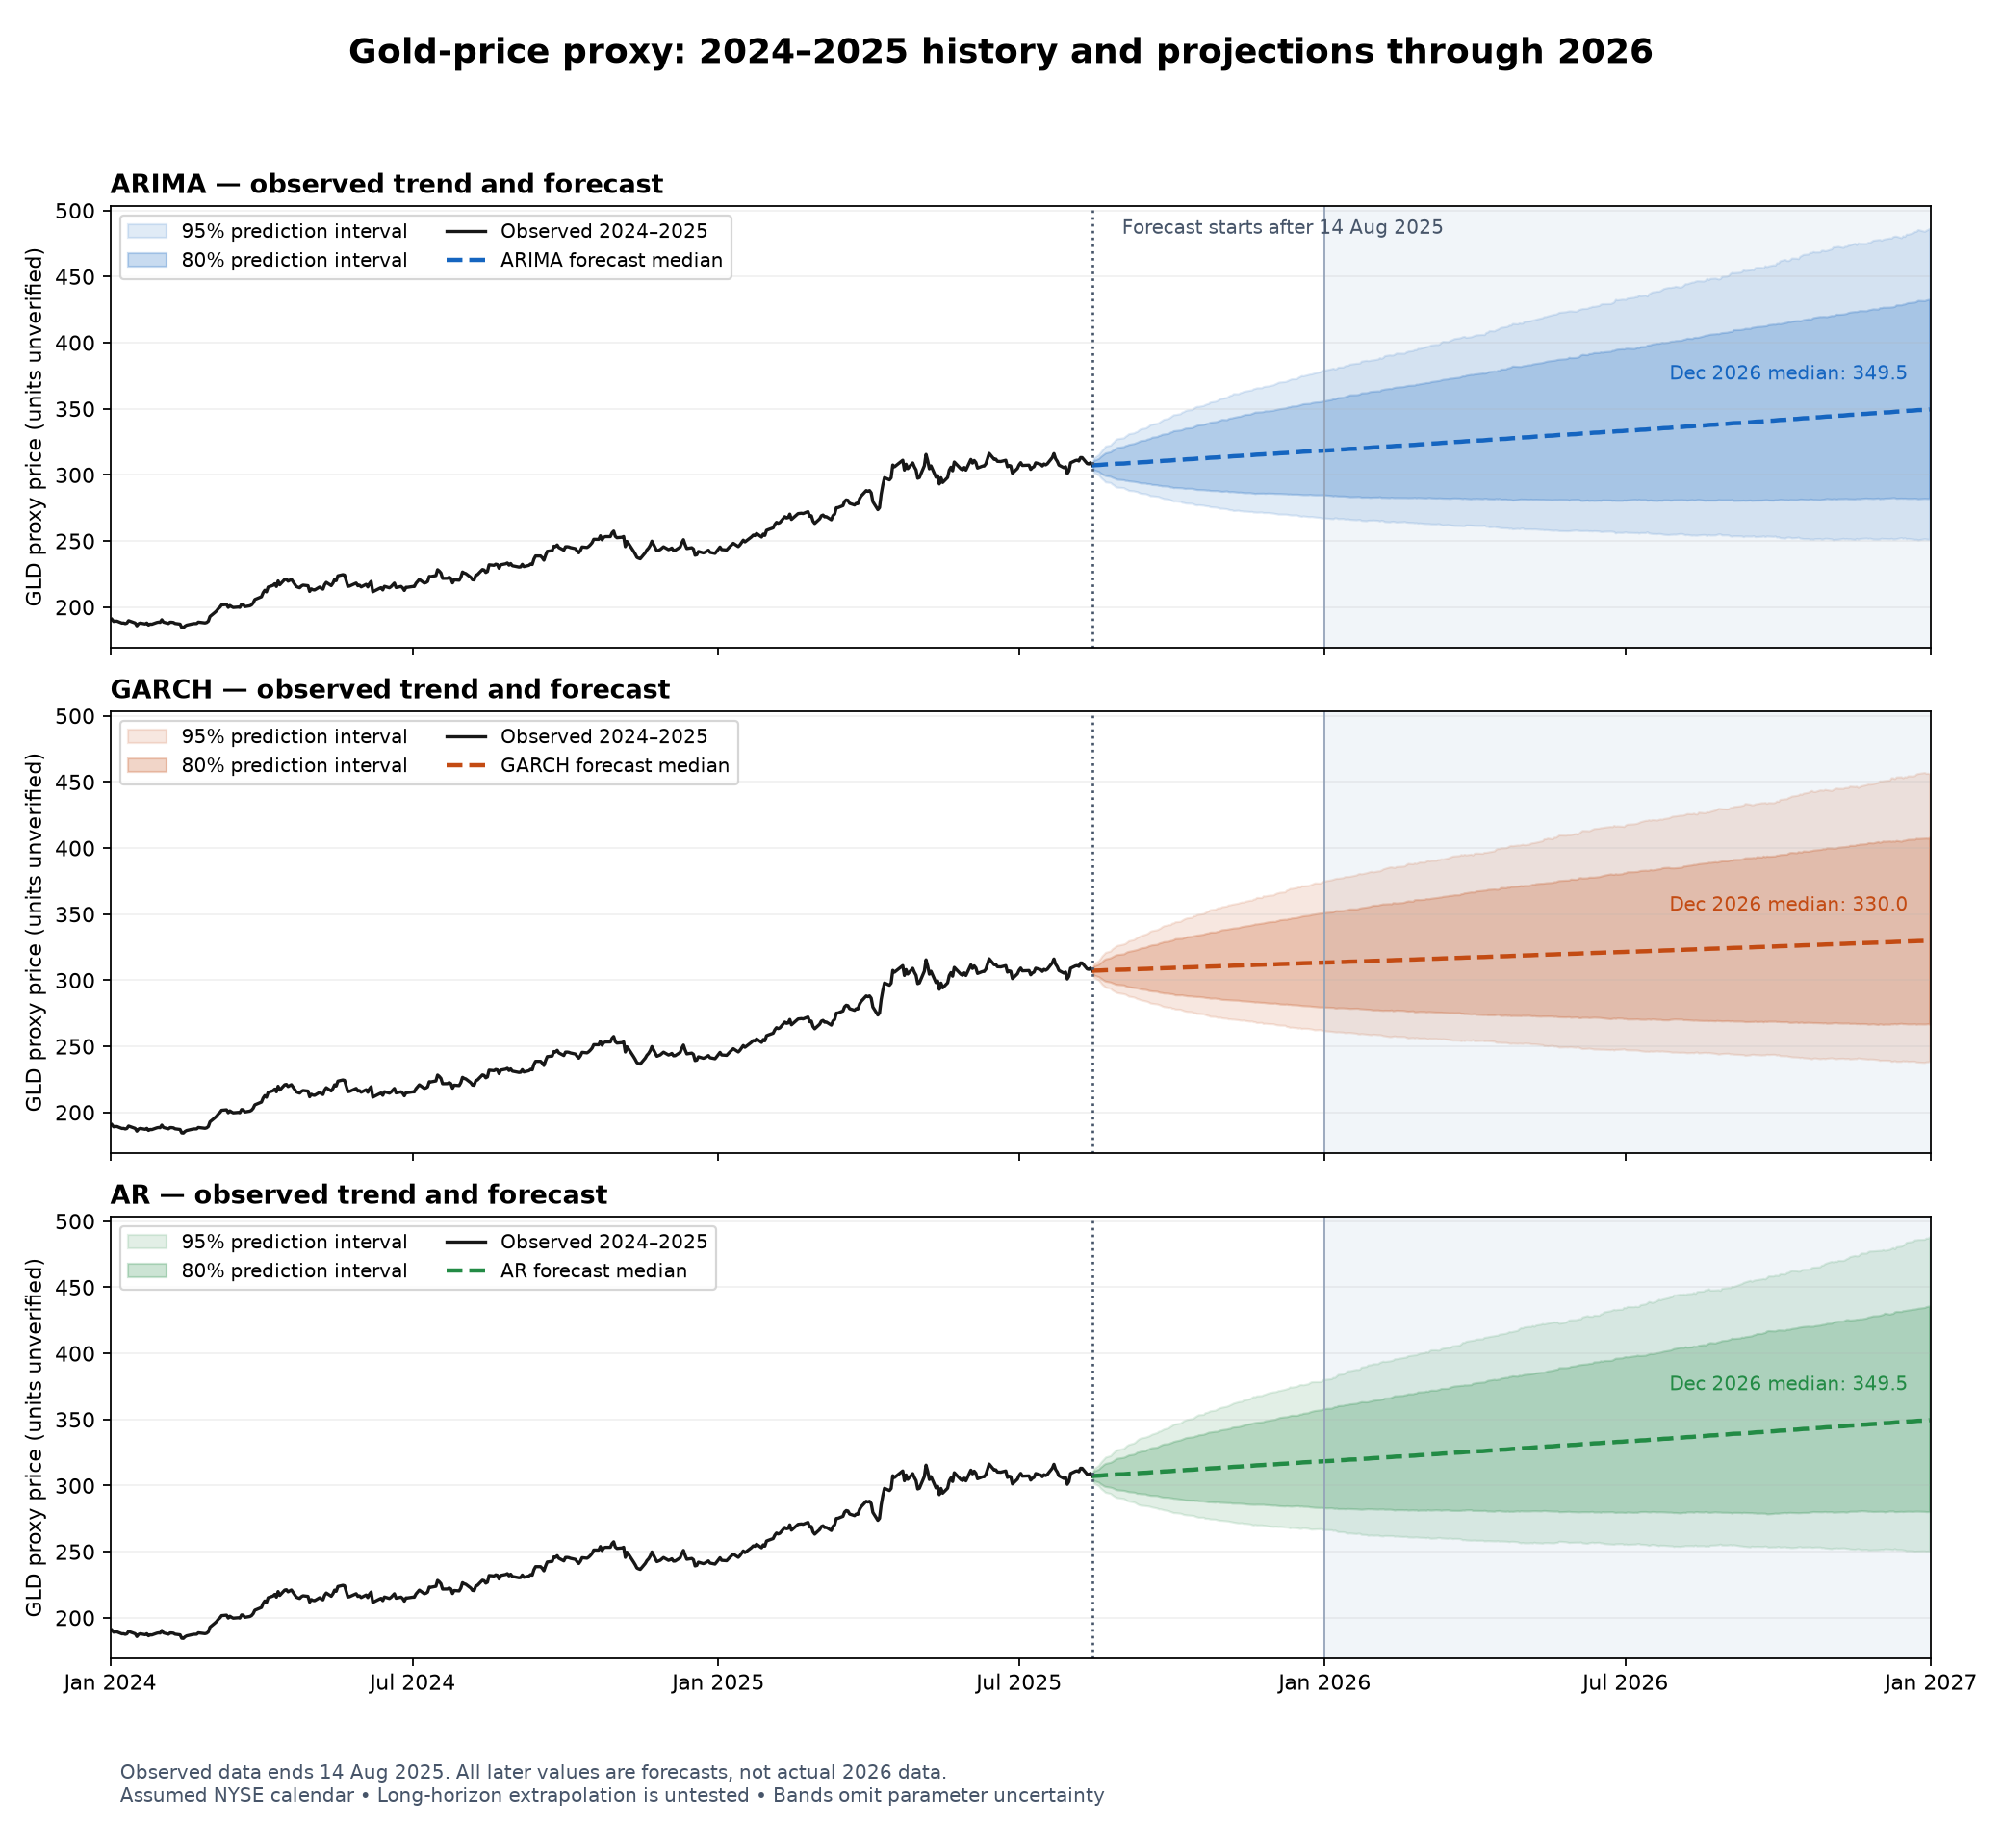

In [6]:
from gold_forecast.projection import generate_projection
from gold_forecast.data import load_data
spec = json.loads((run / 'frozen.json').read_text())
data, input_quality = load_data(root / spec['config']['input'], spec['config'])
assert input_quality['sha256'] == manifest['input_sha256']
projection_dir = run / 'projection_2026'
if not (projection_dir / 'forecast_2024_2026.png').exists():
    generate_projection(data.GLD, spec, run)
projected = pd.read_csv(projection_dir / 'forecasts.csv')
assert projected.actual_price.isna().all()
display(projected[projected.target_date == '2026-12-31'][['model', 'target_date', 'point_price', 'lower80', 'upper80', 'lower95', 'upper95']])
display(Image(filename=str(projection_dir / 'forecast_2024_2026.png')))
